# TD05 — k plus proches voisins et réseaux RBF

## Objectif

Ce TD accompagne le chapitre « 7 - Réseaux RBF ». On y implémente deux modèles qui raisonnent par **proximité** :

- les **k plus proches voisins** (k-NN) : pas d'entraînement, vote des `k` points d'entraînement les plus proches ;
- un **réseau RBF** : une couche de neurones gaussiens centrés sur des points d'entraînement, suivie d'un neurone de sortie sigmoïde, seul à être entraîné.

On les compare ensuite à un perceptron multicouche (MLP) sur trois jeux de données : courbes d'apprentissage, accuracy / précision / rappel, et comportement loin des données. En bonus, on étudie l'effet de la largeur `sigma` des neurones RBF.

## Préambule

Les cellules ci-dessous sont fournies : alias de types, générateurs de données, classe `MLP` (celle du TD04), fonctions de tracé et métriques d'évaluation.

Le pas d'apprentissage `LR = 0.5` et la graine d'initialisation des poids (`seed=0`) sont fixés : ce sont les valeurs par défaut de `MLP` et de `fit`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Alias de types pour les tableaux numpy
Vec = np.ndarray[tuple[int], np.dtype[np.float64]]        # vecteur 1D de flottants
Mat = np.ndarray[tuple[int, int], np.dtype[np.float64]]   # matrice 2D de flottants

### Générateurs de données

Chaque générateur renvoie `X` de forme $(n, 2)$ et les cibles `t` de forme $(n, 1)$, en flottants `0.` / `1.`. L'argument `seed` fixe le tirage. `split` mélange un jeu et le découpe en entraînement, test, et un reste mis de côté.

In [2]:
def make_blobs_imbalanced(n: int, noise: float = 0.6, pos_frac: float = 0.1, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux nuages gaussiens, classe 1 minoritaire.

    Classe 0 centrée en (0, 0), classe 1 centrée en (1, 1) ; chaque point est
    de classe 1 avec la probabilité `pos_frac`.

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    lab = (rng.uniform(size=n) < pos_frac).astype(float)
    centers = np.where(lab[:, None] == 1, [1.0, 1.0], [0.0, 0.0])
    X = centers + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None]


def make_moons(n: int, noise: float = 0.3, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux demi-lunes entrelacées, bruit gaussien d'écart-type `noise`.

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    a = rng.uniform(0.0, np.pi, size=n)
    lab = rng.integers(0, 2, size=n)
    x = np.where(lab == 0, np.cos(a), 1.0 - np.cos(a))
    y = np.where(lab == 0, np.sin(a), 0.5 - np.sin(a))
    X = np.c_[x, y] + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None].astype(float)


def make_circles(n: int, noise: float = 0.1, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux cercles concentriques : classe 0 de rayon 0.5, classe 1 de rayon 1.

    Le bruit gaussien d'écart-type `noise` s'applique au rayon.

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    lab = rng.integers(0, 2, size=n)
    r = np.where(lab == 0, 0.5, 1.0) + rng.normal(0.0, noise, size=n)
    a = rng.uniform(0.0, 2 * np.pi, size=n)
    return np.c_[r * np.cos(a), r * np.sin(a)], lab[:, None].astype(float)


def split(X: Mat, t: Mat, n_train: int, n_test: int, seed: int = 0) -> tuple[Mat, Mat, Mat, Mat, Mat, Mat]:
    """Mélange les exemples puis renvoie X_tr, t_tr, X_te, t_te, X_rest, t_rest.

    Les `n_train` premiers exemples pour l'entraînement, les `n_test`
    suivants pour le test, le reste est mis de côté.
    """
    perm = np.random.default_rng(seed).permutation(len(X))
    X, t = X[perm], t[perm]
    a, b = n_train, n_train + n_test
    return X[:a], t[:a], X[a:b], t[a:b], X[b:], t[b:]

### Le réseau MLP

`MLP(sizes, seed=0)` : couches cachées en tanh, sortie sigmoïde, coût $E = \tfrac12\,\operatorname{mean}\sum_k (Y_k - T_k)^2$. `predict(X)` renvoie la probabilité de la classe 1, de forme $(N, 1)$.

`fit(X, t, epochs, lr=LR, X_test=None, t_test=None)` effectue une étape de descente de gradient par époque et renvoie l'historique : clés `"train_loss"`, `"train_err"` et, si un jeu de test est fourni, `"test_loss"`, `"test_err"` (taux d'erreur). L'entrée `i` correspond au modèle après `i + 1` étapes.

In [3]:
LR = 0.5  # pas d'apprentissage, commun à tout le TD


class MLP:
    def __init__(self, sizes: list[int], seed: int = 0):
        rng = np.random.default_rng(seed)
        self.sizes = list(sizes)
        self.Ws: list[Mat] = []
        self.bs: list[Vec] = []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            self.Ws.append(rng.normal(0.0, 0.5, size=(n_out, n_in)))
            self.bs.append(np.zeros(n_out))

    def _forward(self, X: Mat) -> tuple[list[Mat], list[Mat]]:
        """Passe avant : renvoie (As, Zs), activations (avec Y0 = X en tête) et pré-activations."""
        A = X
        As = [A]
        Zs = []
        n = len(self.Ws)
        for l, (W, b) in enumerate(zip(self.Ws, self.bs)):
            Z = A @ W.T + b
            Zs.append(Z)
            A = 1.0 / (1.0 + np.exp(-Z)) if l == n - 1 else np.tanh(Z)
            As.append(A)
        return As, Zs

    def backward(self, X: Mat, t: Mat) -> list[tuple[Mat, Vec]]:
        """Passe arrière : liste de (dW_l, db_l), une paire par couche."""
        As, Zs = self._forward(X)
        N = X.shape[0]
        Y = As[-1]
        delta = (Y - t) * Y * (1.0 - Y)
        grads: list[tuple[Mat, Vec]] = []
        for l in reversed(range(len(self.Ws))):
            dW = delta.T @ As[l] / N
            db = delta.mean(axis=0)
            grads.append((dW, db))
            if l > 0:
                delta = (delta @ self.Ws[l]) * (1.0 - np.tanh(Zs[l - 1]) ** 2)
        grads.reverse()
        return grads

    def step(self, X: Mat, t: Mat, lr: float) -> None:
        """Une étape de descente de gradient sur le jeu (X, t)."""
        for l, (dW, db) in enumerate(self.backward(X, t)):
            self.Ws[l] = self.Ws[l] - lr * dW
            self.bs[l] = self.bs[l] - lr * db

    def predict(self, X: Mat) -> Mat:
        """Probabilités de la classe 1, de forme (N, 1)."""
        return self._forward(X)[0][-1]

    def loss(self, X: Mat, t: Mat) -> float:
        """Coût : E = (1/2) · mean(Σ_k (Y_k - T_k)²)."""
        return 0.5 * float(np.mean(np.sum((self.predict(X) - t) ** 2, axis=1)))

    def error_rate(self, X: Mat, t: Mat, threshold: float = 0.5) -> float:
        """Proportion d'exemples mal classés (classe 1 prédite si la probabilité est supérieure ou égale à `threshold`)."""
        return float(np.mean((self.predict(X) >= threshold) != (t > 0.5)))

    def fit(self, X: Mat, t: Mat, epochs: int, lr: float = LR,
            X_test: Mat | None = None, t_test: Mat | None = None) -> dict[str, list[float]]:
        """Entraîne le réseau (une étape par époque) et renvoie l'historique.

        Clés : `"train_loss"`, `"test_loss"` (coûts) et `"train_err"`, `"test_err"`
        (taux d'erreur). L'entrée i est mesurée après i + 1 étapes ; les listes
        `"test_loss"` et `"test_err"` restent vides sans jeu de test.
        """
        history: dict[str, list[float]] = {"train_loss": [], "test_loss": [], "train_err": [], "test_err": []}
        has_test = X_test is not None and t_test is not None
        for _ in range(epochs):
            self.step(X, t, lr)
            history["train_loss"].append(self.loss(X, t))
            history["train_err"].append(self.error_rate(X, t))
            if has_test:
                history["test_loss"].append(self.loss(X_test, t_test))
                history["test_err"].append(self.error_rate(X_test, t_test))
        return history

### Tracés et métriques

`plot_curves` superpose des courbes d'apprentissage (train en pointillés, test en trait plein). `plot_data` affiche un nuage de points coloré par classe. `plot_decision` affiche la sortie d'un modèle (fond), sa frontière à 0.5 (trait noir) et les points ; il accepte tout modèle muni d'une méthode `predict(X)` renvoyant un tableau $(N, 1)$, et `margin` règle la marge de la zone tracée autour des points.

`classify`, `evaluate` et `show` sont celles du TD04 : prédictions 0/1 au seuil 0.5, matrice de confusion et métriques (accuracy, précision, rappel), affichage d'une ligne de résultats.

In [4]:
def plot_curves(histories: dict[str, dict[str, list[float]]], metric: str = "loss",
                logx: bool = True, ax=None, test_label: str = "test"):
    """Courbes d'apprentissage de plusieurs historiques sur un même graphique.

    `metric="loss"` trace le coût, `metric="err"` les taux d'erreur ;
    `test_label` est le nom de la courbe en trait plein dans la légende.
    """
    if ax is None:
        fig, ax = plt.subplots()
    k_tr, k_va = ("train_loss", "test_loss") if metric == "loss" else ("train_err", "test_err")
    if len(histories) == 1:
        h = next(iter(histories.values()))
        x = np.arange(1, len(h[k_tr]) + 1)
        ax.plot(x, h[k_tr], color="C0", ls="--", lw=1, label="train")
        if h[k_va]:
            ax.plot(x, h[k_va], color="C0", label=test_label)
    else:
        has_test = False
        for i, (name, h) in enumerate(histories.items()):
            c = f"C{i}"
            x = np.arange(1, len(h[k_tr]) + 1)
            ax.plot(x, h[k_tr], color=c, ls="--", lw=1)
            if h[k_va]:
                ax.plot(x, h[k_va], color=c, label=name)
                has_test = True
            else:
                ax.plot([], [], color=c, ls="--", label=name)
        ax.plot([], [], color="gray", ls="--", lw=1, label="train")
        if has_test:
            ax.plot([], [], color="gray", label=test_label)
    ax.set_xlabel("époque")
    ax.set_ylabel("coût" if metric == "loss" else "taux d'erreur")
    if logx:
        ax.set_xscale("log")
    if metric == "loss":
        ax.set_yscale("log")
    ax.legend()
    ax.grid(True)
    return ax


def plot_data(X: Mat, t: Mat, ax=None):
    """Nuage de points coloré par classe (classe 0 en rouge, classe 1 en bleu), avec légende."""
    if ax is None:
        fig, ax = plt.subplots()
    for k, color in ((0, "tab:red"), (1, "tab:blue")):
        mask = t.ravel() == k
        ax.scatter(X[mask, 0], X[mask, 1], color=color, label=f"classe {k}",
                   edgecolors="w", linewidths=0.5, s=25, zorder=3)
    ax.legend(loc="upper left")
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True)
    return ax


def plot_decision(model, X: Mat, t: Mat, ax=None, margin: float = 0.3, n_grid: int = 200):
    """Sortie de `model` (fond), frontière à 0.5 (trait noir) et points (X, t).

    `model` est tout objet muni d'une méthode `predict(X)` renvoyant un tableau
    (N, 1) de valeurs dans [0, 1]. `margin` est la marge tracée autour des points.
    """
    if ax is None:
        fig, ax = plt.subplots()
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - margin, X[:, 0].max() + margin, n_grid),
                         np.linspace(X[:, 1].min() - margin, X[:, 1].max() + margin, n_grid))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.linspace(0, 1, 21), cmap="RdBu", alpha=0.6)
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=2)
    plot_data(X, t, ax=ax)
    return ax

In [5]:
def classify(Y: Mat, threshold: float = 0.5) -> Vec:
    """Prédictions 0/1 (forme (N,)) à partir des probabilités `Y` de forme (N, 1)."""
    return (Y.ravel() >= threshold).astype(float)


def confusion(t: Vec | Mat, y: Vec | Mat) -> tuple[int, int, int, int]:
    """Comptes (TP, FP, TN, FN) ; `t` et `y` de forme (N,) ou (N, 1)."""
    t, y = t.ravel(), y.ravel()
    tp = int(np.sum((t == 1) & (y == 1)))
    fp = int(np.sum((t == 0) & (y == 1)))
    tn = int(np.sum((t == 0) & (y == 0)))
    fn = int(np.sum((t == 1) & (y == 0)))
    return tp, fp, tn, fn


def evaluate(t: Vec | Mat, y: Vec | Mat) -> dict[str, float]:
    """Comptes "TP", "FP", "TN", "FN" et métriques "accuracy", "precision", "recall"."""
    tp, fp, tn, fn = confusion(t, y)
    return {"TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "accuracy": (tp + tn) / (tp + fp + tn + fn),
            "precision": tp / (tp + fp) if tp + fp > 0 else 0.0,
            "recall": tp / (tp + fn) if tp + fn > 0 else 0.0}


def show(name: str, res: dict[str, float]) -> None:
    counts = "  ".join(f"{k}={int(res[k])}" for k in ("TP", "FP", "TN", "FN"))
    print(f"{name:18s} {counts}  | accuracy={res['accuracy']:.3f}  "
          f"précision={res['precision']:.3f}  rappel={res['recall']:.3f}")


def error_rate(model, X: Mat, t: Mat) -> float:
    """Proportion d'exemples mal classés par `model` (seuil 0.5)."""
    return float(np.mean(classify(model.predict(X)) != t.ravel()))

### Les données

Trois jeux de 1200 points, découpés en **200 points d'entraînement** et **1000 points de test** :

- **cercles** : deux cercles concentriques ;
- **lunes** : deux demi-lunes entrelacées ;
- **blobs** : deux nuages gaussiens qui se chevauchent, la classe 1 étant **minoritaire** (≈ 10 % des points : 20 sur 200 à l'entraînement).

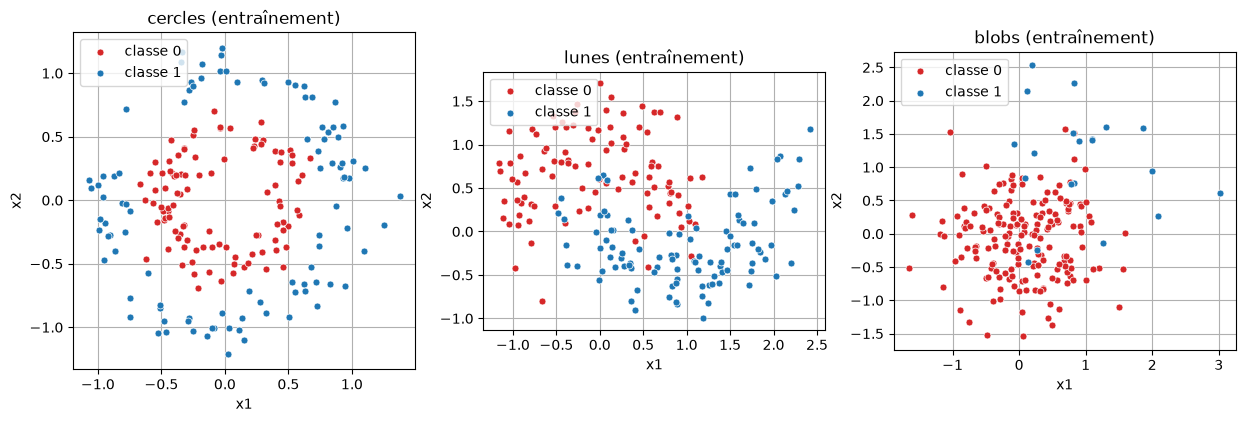

In [6]:
X_ci_tr, t_ci_tr, X_ci_te, t_ci_te, _, _ = split(*make_circles(1200, seed=1), 200, 1000)
X_mo_tr, t_mo_tr, X_mo_te, t_mo_te, _, _ = split(*make_moons(1200, seed=1), 200, 1000)
X_bl_tr, t_bl_tr, X_bl_te, t_bl_te, _, _ = split(*make_blobs_imbalanced(1200, seed=1), 200, 1000, seed=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, X, t) in zip(axes, [("cercles", X_ci_tr, t_ci_tr), ("lunes", X_mo_tr, t_mo_tr),
                                   ("blobs", X_bl_tr, t_bl_tr)]):
    plot_data(X, t, ax=ax)
    ax.set_title(f"{name} (entraînement)")
plt.show()

## 1. k plus proches voisins

### 1.1 Prédire par vote des voisins

Pour classer une requête $q$, on calcule sa distance à **tous** les points d'entraînement, on garde les `k` plus proches et on répond l'étiquette **majoritaire** parmi eux. Il n'y a pas d'entraînement : tout le calcul se fait à la prédiction.

Pour une requête `q` de forme $(d,)$ et des points d'entraînement `X` de forme $(N, d)$, l'expression `X - q` soustrait `q` à **chaque ligne** de `X` : elle donne un tableau $(N, d)$ dont la ligne `i` est `X[i] - q`. Les distances au carré de `q` à tous les points s'obtiennent donc par `((X - q) ** 2).sum(axis=1)`, de forme $(N,)$.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 1</legend>

Complétez `knn_predict`, qui renvoie l'étiquette majoritaire (`0.` ou `1.`) des `k` plus proches voisins d'**une** requête `q` :

1. calculer les distances au carré (elles donnent le même classement que les distances) de `q` à tous les points d'entraînement, de forme $(N,)$ ;
2. trouver les indices des `k` plus proches voisins (`np.argsort`, puis garder les `k` premiers) ;
3. voter : la moyenne des étiquettes des voisins est la proportion de voisins de classe 1 ; on répond 1 si elle vaut au moins 0.5 (en cas d'égalité, on répond donc 1).

</fieldset>

In [7]:
def knn_predict(X: Mat, t: Mat, q: Vec, k: int = 1) -> float:
    """Étiquette majoritaire des `k` plus proches voisins de la requête `q`.

    `X` : points d'entraînement (N, d), `t` : leurs étiquettes (N, 1),
    `q` : une requête (d,). Renvoie 0. ou 1. ; en cas d'égalité des votes,
    la réponse est 1.
    """
    # BEGIN
    ## Indice : d2 = ((X - q) ** 2).sum(axis=1), puis np.argsort(d2)[:k], puis moyenne des étiquettes.
    d2 = ((X - q) ** 2).sum(axis=1)
    idx = np.argsort(d2)[:k]
    return float(t.ravel()[idx].mean() >= 0.5)
    # END

In [8]:
def check_knn():
    X_t = np.array([[0.0, 0.0], [2.0, 0.0], [0.0, 2.0]])
    t_t = np.array([[0.0], [1.0], [1.0]])
    assert [knn_predict(X_t, t_t, q, k=1) for q in X_t] == [0.0, 1.0, 1.0], "k=1 : chaque point est son propre voisin"
    assert knn_predict(X_t, t_t, np.array([0.1, 0.0]), k=1) == 0.0, "k=1 incorrect"
    assert knn_predict(X_t, t_t, np.array([1.9, 0.0]), k=1) == 1.0, "k=1 incorrect"
    assert knn_predict(X_t, t_t, np.array([0.0, 0.0]), k=3) == 1.0, "k=3 : vote majoritaire incorrect"
    assert knn_predict(X_t, t_t, np.array([0.0, 0.1]), k=2) == 1.0, "égalité des votes : la réponse doit être 1"
    print("knn_predict check — OK")

check_knn()

knn_predict check — OK


### 1.2 Frontières de décision

La classe `KNN` ci-dessous (fournie) applique `knn_predict` à chaque requête et range les réponses dans un tableau $(M, 1)$ : elle a ainsi la même interface que les réseaux (`predict(X)`), ce qui permet d'utiliser `plot_decision` et les métriques.

On affiche ensuite la frontière de décision du k-NN sur les lunes pour trois valeurs de `k`, avec l'accuracy sur le jeu de test.

In [9]:
class KNN:
    """k plus proches voisins : mémorise (X, t), tout le calcul se fait dans `predict`."""

    def __init__(self, X: Mat, t: Mat, k: int):
        self.X, self.t, self.k = X, t, k

    def predict(self, Xq: Mat) -> Mat:
        """Prédictions 0. / 1. de forme (M, 1), une requête (ligne de `Xq`) à la fois."""
        return np.array([[knn_predict(self.X, self.t, q, self.k)] for q in Xq])

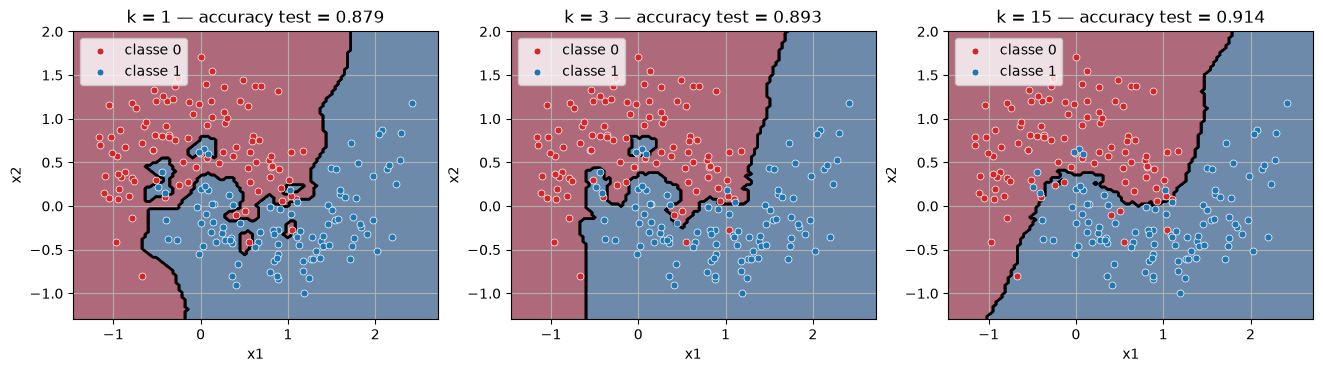

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axes, (1, 3, 15)):
    knn = KNN(X_mo_tr, t_mo_tr, k)
    acc = evaluate(t_mo_te, classify(knn.predict(X_mo_te)))["accuracy"]
    plot_decision(knn, X_mo_tr, t_mo_tr, ax=ax, n_grid=120)
    ax.set_title(f"k = {k} — accuracy test = {acc:.3f}")
plt.show()

## 2. Réseau RBF

### 2.1 La couche RBF

Un neurone RBF de centre $c$ et de largeur $\sigma$ calcule

$$\varphi(x) = \exp\left(-\frac{\|x - c\|^2}{2\sigma^2}\right)$$

qui vaut 1 au centre et tend vers 0 quand $x$ s'en éloigne. Avec $K$ centres rangés dans une matrice `centres` de forme $(K, d)$, la couche RBF transforme les $N$ exemples de `X` en une matrice `Phi` de forme $(N, K)$ : `Phi[i, k]` est l'activation du neurone `k` pour l'exemple `i`.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 2</legend>

Complétez `rbf_features`, qui renvoie la matrice `Phi` de forme $(N, K)$. On la remplit **colonne par colonne** : pour chaque centre `c = centres[k]`, la colonne `Phi[:, k]` contient l'activation du neurone `k` pour tous les exemples. Les distances au carré de tous les exemples à `c` se calculent comme dans `knn_predict` : `((X - c) ** 2).sum(axis=1)`.

</fieldset>

In [11]:
def rbf_features(X: Mat, centres: Mat, sigma: float) -> Mat:
    """Activations des neurones RBF : `Phi[i, k] = exp(-||X[i] - centres[k]||² / (2 sigma²))`.

    `X` : (N, d), `centres` : (K, d). Renvoie un tableau (N, K).
    """
    # BEGIN
    ## Indice : Phi = np.zeros((len(X), len(centres))), puis une boucle sur les centres.
    Phi = np.zeros((len(X), len(centres)))
    for k, c in enumerate(centres):
        d2 = ((X - c) ** 2).sum(axis=1)
        Phi[:, k] = np.exp(-d2 / (2 * sigma ** 2))
    return Phi
    # END

In [12]:
def check_rbf_features():
    X = np.array([[0.0, 0.0], [1.0, 0.0], [3.0, 4.0]])
    C = np.array([[0.0, 0.0], [1.0, 0.0]])
    P = rbf_features(X, C, sigma=1.0)
    assert P.shape == (3, 2), "Phi doit être de forme (N, K)"
    assert np.allclose(P[0], [1.0, np.exp(-0.5)]), "Phi[0] incorrect"
    assert np.allclose(P[1], [np.exp(-0.5), 1.0]), "Phi[1] incorrect"
    assert np.allclose(P[2, 0], np.exp(-12.5)), "Phi[2, 0] incorrect"
    assert np.allclose(rbf_features(X, C[:1], sigma=2.0)[:, 0], np.exp(-np.array([0, 1, 25]) / 8)), "sigma mal pris en compte"
    print("rbf_features check — OK")

check_rbf_features()

rbf_features check — OK


Les centres sont placés par `kmeans_centres` (fournie), qui applique l'algorithme k-means vu en cours : partir de `K` points d'entraînement, puis répéter (1) rattacher chaque point au centre le plus proche, (2) déplacer chaque centre à la moyenne de ses points, jusqu'à ce que les centres ne bougent plus. Les cibles ne sont pas utilisées : seule la position des points compte.

On affiche ci-dessous, sur les cercles, les 30 centres obtenus et l'activation de trois d'entre eux.

In [13]:
K = 30        # nombre de centres
SIGMA = 0.5   # largeur des neurones RBF


def kmeans_centres(X: Mat, K: int, seed: int = 0, max_iter: int = 100) -> Mat:
    """Centres de `K` paquets de `X` par k-means (algorithme de Lloyd) : tableau (K, d).

    Les centres initiaux sont `K` points de `X` tirés au hasard ; un centre dont le paquet est vide reste en place.
    """
    idx = np.random.default_rng(seed).choice(len(X), K, replace=False)
    centres = X[idx].copy()
    for _ in range(max_iter):
        # affectation : indice du centre le plus proche de chaque point
        d2 = np.stack([((X - c) ** 2).sum(axis=1) for c in centres], axis=1)  # (N, K)
        label = d2.argmin(axis=1)
        # mise à jour : chaque centre va à la moyenne de son paquet
        new = np.array([X[label == k].mean(axis=0) if (label == k).any() else centres[k] for k in range(K)])
        if np.allclose(new, centres):
            break
        centres = new
    return centres

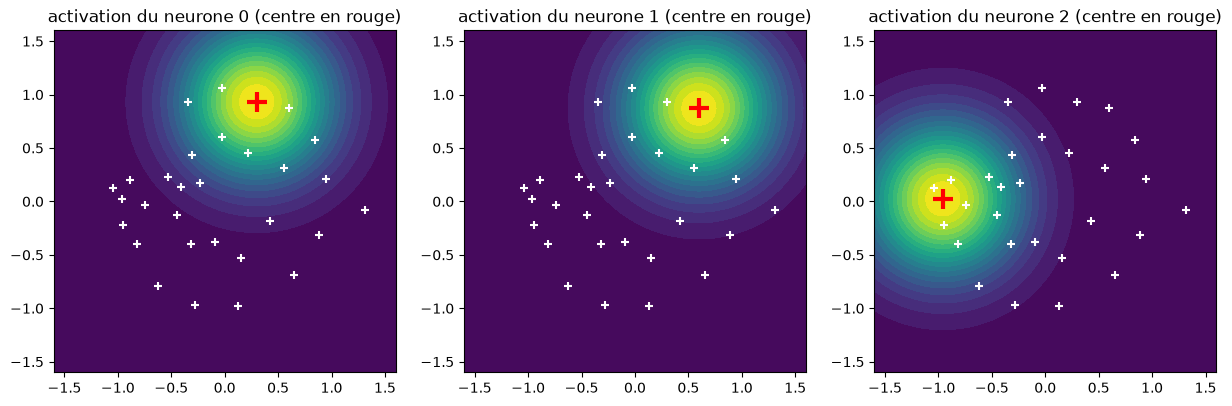

In [14]:
centres_ci = kmeans_centres(X_ci_tr, K)
xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 150), np.linspace(-1.6, 1.6, 150))
Phi_grid = rbf_features(np.c_[xx.ravel(), yy.ravel()], centres_ci, SIGMA)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, k in zip(axes, (0, 1, 2)):
    ax.contourf(xx, yy, Phi_grid[:, k].reshape(xx.shape), levels=20, cmap="viridis")
    ax.scatter(centres_ci[:, 0], centres_ci[:, 1], c="w", marker="+", s=40)
    ax.scatter(*centres_ci[k], c="r", marker="+", s=200, linewidths=3)
    ax.set_aspect("equal")
    ax.set_title(f"activation du neurone {k} (centre en rouge)")
plt.show()


### 2.2 Le réseau complet

Le réseau RBF calcule $y = \text{sigmoid}\left(\sum_k w_k\,\varphi_k(x) + b\right)$. Une fois les centres et `sigma` fixés, seuls $w$ et $b$ sont appris : c'est un réseau à **une seule couche** dont l'entrée est `Phi(X)` au lieu de `X`. On réutilise donc la classe `MLP` avec `sizes = [K, 1]` : elle n'a pas de couche cachée, sa couche unique est linéaire puis sigmoïde.

Le constructeur de `RBF` (fourni) mémorise les centres et `sigma`, et crée ce réseau de sortie `self.out`.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 3</legend>

Complétez les deux méthodes de `RBF` ; chacune calcule d'abord les activations RBF avec `rbf_features`, puis délègue à `self.out` :

1. `predict(X)` : probabilité de la classe 1, de forme $(N, 1)$ ;
2. `fit(X, t, epochs, lr, X_test, t_test)` : entraîne `self.out` sur les activations de `X` et renvoie l'historique de `self.out.fit`. Si un jeu de test est fourni, `self.out.fit` doit recevoir **ses activations** comme `X_test`. Calculez les activations une seule fois, avant l'entraînement.

</fieldset>

In [15]:
class RBF:
    """Réseau RBF : couche gaussienne fixe (`centres`, `sigma`) puis neurone de sortie sigmoïde."""

    def __init__(self, centres: Mat, sigma: float, seed: int = 0):
        self.centres = centres
        self.sigma = sigma
        self.out = MLP([len(centres), 1], seed=seed)

    def predict(self, X: Mat) -> Mat:
        """Probabilité de la classe 1, de forme (N, 1)."""
        # BEGIN
        ## Indice: réutiliser rbf_features, et self.out.predict
        return self.out.predict(rbf_features(X, self.centres, self.sigma))
        # END

    def fit(self, X: Mat, t: Mat, epochs: int, lr: float = LR,
            X_test: Mat | None = None, t_test: Mat | None = None) -> dict[str, list[float]]:
        """Entraîne le neurone de sortie sur les activations RBF ; même historique que `MLP.fit`."""
        # BEGIN
        ## Indice: similaire à predict, sauf qu'on appelle self.out.fit (en prenant aussi en compte l'éventuel X_test)
        Phi = rbf_features(X, self.centres, self.sigma)
        Phi_test = None if X_test is None else rbf_features(X_test, self.centres, self.sigma)
        return self.out.fit(Phi, t, epochs, lr, X_test=Phi_test, t_test=t_test)
        # END

In [16]:
def check_rbf():
    C = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
    X = np.array([[0.2, 0.1], [0.9, -0.3], [-0.4, 1.2], [1.5, 1.5]])
    t = np.array([[0.0], [1.0], [1.0], [0.0]])
    Phi = rbf_features(X, C, 0.7)

    # référence : un MLP([3, 1]) entraîné directement sur les activations
    ref = MLP([3, 1], seed=0)
    h_ref = ref.fit(Phi, t, epochs=3, lr=0.5, X_test=Phi[:2], t_test=t[:2])

    rbf = RBF(C, 0.7, seed=0)
    assert np.array_equal(rbf.predict(X), rbf.out.predict(Phi)), "predict : appliquer self.out à rbf_features(X, ...)"
    assert rbf.predict(X).shape == (4, 1), "predict doit renvoyer un tableau (N, 1)"
    h = rbf.fit(X, t, epochs=3, lr=0.5, X_test=X[:2], t_test=t[:2])
    assert set(h) == {"train_loss", "test_loss", "train_err", "test_err"}, "fit doit renvoyer l'historique de self.out.fit"
    assert len(h["test_loss"]) == 3, "historique de test absent : passer les activations de X_test à self.out.fit"
    assert np.allclose(h["train_loss"], h_ref["train_loss"]) and np.allclose(h["test_loss"], h_ref["test_loss"]),         "fit : entraîner self.out sur rbf_features(X, ...) (et sur celles de X_test pour le test)"
    assert np.allclose(rbf.out.Ws[0], ref.Ws[0]) and np.allclose(rbf.out.bs[0], ref.bs[0]), "poids différents de la référence"
    print("RBF check — OK")

check_rbf()

RBF check — OK


On entraîne un réseau RBF sur les cercles et on affiche sa frontière, avec les centres (croix noires).

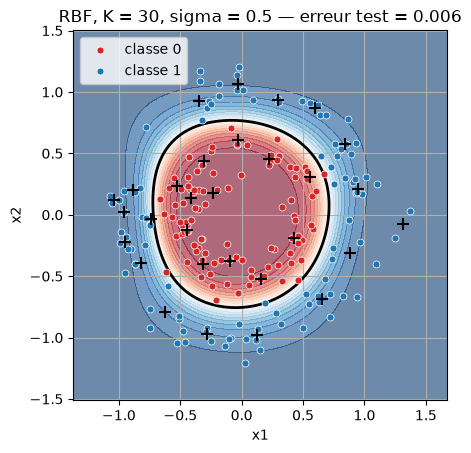

In [17]:
rbf_ci = RBF(kmeans_centres(X_ci_tr, K), SIGMA)
rbf_ci.fit(X_ci_tr, t_ci_tr, epochs=2000)
ax = plot_decision(rbf_ci, X_ci_tr, t_ci_tr)
ax.scatter(rbf_ci.centres[:, 0], rbf_ci.centres[:, 1], c="k", marker="+", s=80, zorder=4)
ax.set_title(f"RBF, K = {K}, sigma = {SIGMA} — erreur test = {error_rate(rbf_ci, X_ci_te, t_ci_te):.3f}")
plt.show()

## 3. Comparaison k-NN / RBF / MLP

On entraîne, sur chacun des trois jeux, un réseau RBF (`K = 30` centres, `sigma = 0.5`) et un MLP à une couche cachée de 16 neurones tanh (`MLP([2, 16, 1])`), avec le même pas d'apprentissage et le même nombre d'époques. Le k-NN (`k = 15`) n'a pas d'entraînement : il n'a pas de courbe d'apprentissage, mais il figure dans les métriques.

### 3.1 Courbes d'apprentissage

La cellule suivante entraîne les modèles (quelques secondes) puis trace les taux d'erreur au fil des époques (échelle logarithmique en abscisse).

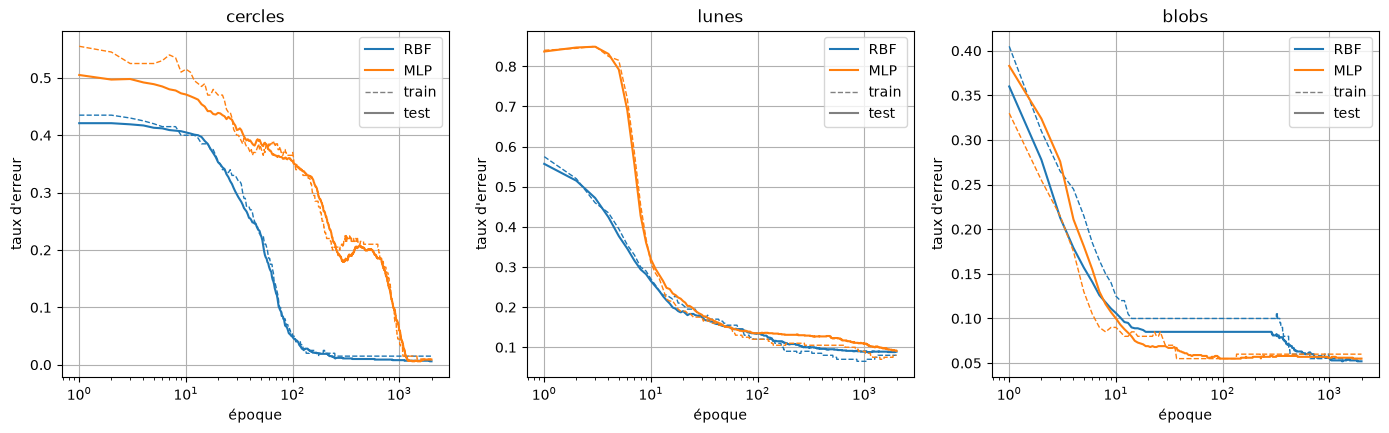

erreur de test après 10 / 100 / 500 / 2000 époques
cercles  RBF: 0.405 / 0.049 / 0.010 / 0.006
cercles  MLP: 0.471 / 0.355 / 0.199 / 0.009
lunes    RBF: 0.265 / 0.134 / 0.095 / 0.089
lunes    MLP: 0.319 / 0.135 / 0.123 / 0.091
blobs    RBF: 0.106 / 0.085 / 0.063 / 0.052
blobs    MLP: 0.100 / 0.055 / 0.058 / 0.055


In [18]:
EPOCHS = 2000
datasets = {
    "cercles": (X_ci_tr, t_ci_tr, X_ci_te, t_ci_te),
    "lunes": (X_mo_tr, t_mo_tr, X_mo_te, t_mo_te),
    "blobs": (X_bl_tr, t_bl_tr, X_bl_te, t_bl_te),
}
models: dict[str, dict] = {}
hists: dict[str, dict[str, dict[str, list[float]]]] = {}
for name, (X_tr, t_tr, X_te, t_te) in datasets.items():
    rbf = RBF(kmeans_centres(X_tr, K), SIGMA)
    h_rbf = rbf.fit(X_tr, t_tr, EPOCHS, X_test=X_te, t_test=t_te)
    mlp = MLP([2, 16, 1])
    h_mlp = mlp.fit(X_tr, t_tr, EPOCHS, X_test=X_te, t_test=t_te)
    models[name] = {"k-NN (k=15)": KNN(X_tr, t_tr, 15), "RBF": rbf, "MLP": mlp}
    hists[name] = {"RBF": h_rbf, "MLP": h_mlp}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, name in zip(axes, datasets):
    plot_curves(hists[name], metric="err", ax=ax)
    ax.set_title(name)
plt.show()

print("erreur de test après 10 / 100 / 500 / 2000 époques")
for name in datasets:
    for m in ("RBF", "MLP"):
        e = hists[name][m]["test_err"]
        print(f"{name:8s} {m}: " + " / ".join(f"{e[i - 1]:.3f}" for i in (10, 100, 500, 2000)))

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 4</legend>

Pour chacun des trois jeux, quel réseau (RBF ou MLP) atteint le plus vite une faible erreur de test ? Sur quel jeu l'écart est-il le plus net ? Expliquez-le, en pensant à ce que chaque modèle doit apprendre (combien de couches, à partir de quelle représentation des données).

</fieldset>

*Votre réponse :*

# TOCLEAR

- **Cercles** : le RBF, nettement. Environ 5 % d'erreur de test après 100 époques et 1 % après 500, quand le MLP est encore vers 35 % puis 20 % (il ne rattrape le RBF qu'en fin d'entraînement).
- **Lunes** : vitesses comparables (≈ 13 % pour les deux après 100 époques), le RBF un peu devant ensuite.
- **Blobs** : c'est le MLP qui atteint son plateau le premier (dès 100 époques) ; le RBF ne le rejoint qu'en fin d'entraînement.

L'écart est le plus net sur les cercles. Le RBF n'apprend qu'**une seule couche**, sur des activations `Phi(X)` déjà adaptées au problème : chaque centre « couvre » une zone de l'anneau ou du disque, et il suffit de pondérer ces zones (problème quasi linéaire, sans plateau). Le MLP doit d'abord construire ses propres caractéristiques par rétropropagation à travers la couche cachée, ce qui est plus lent ; or une frontière circulaire demande de combiner plusieurs demi-plans. Sur les blobs, la frontière est presque une droite : un seul demi-plan suffit au MLP, alors que le RBF doit l'approcher avec ses bosses. L'avantage du RBF dépend donc des données : il est net quand des bosses locales décrivent bien les classes.

### 3.2 Accuracy, précision, rappel

On évalue les trois modèles sur le jeu de **test** de chaque jeu de données (classe 1 = classe positive).

In [19]:
for name, (X_tr, t_tr, X_te, t_te) in datasets.items():
    print(f"--- {name} ({int(t_te.sum())} positifs sur {len(t_te)})")
    for m_name, model in models[name].items():
        show(m_name, evaluate(t_te, classify(model.predict(X_te))))
    print()

--- cercles (491 positifs sur 1000)
k-NN (k=15)        TP=462  FP=3  TN=506  FN=29  | accuracy=0.968  précision=0.994  rappel=0.941
RBF                TP=489  FP=4  TN=505  FN=2  | accuracy=0.994  précision=0.992  rappel=0.996
MLP                TP=488  FP=6  TN=503  FN=3  | accuracy=0.991  précision=0.988  rappel=0.994

--- lunes (492 positifs sur 1000)
k-NN (k=15)        TP=449  FP=43  TN=465  FN=43  | accuracy=0.914  précision=0.913  rappel=0.913
RBF                TP=446  FP=43  TN=465  FN=46  | accuracy=0.911  précision=0.912  rappel=0.907
MLP                TP=446  FP=45  TN=463  FN=46  | accuracy=0.909  précision=0.908  rappel=0.907

--- blobs (85 positifs sur 1000)
k-NN (k=15)        TP=35  FP=7  TN=908  FN=50  | accuracy=0.943  précision=0.833  rappel=0.412
RBF                TP=46  FP=13  TN=902  FN=39  | accuracy=0.948  précision=0.780  rappel=0.541
MLP                TP=47  FP=17  TN=898  FN=38  | accuracy=0.945  précision=0.734  rappel=0.553



<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 5</legend>

1. Sur les cercles et les lunes, comparez les trois modèles : l'un d'eux se distingue-t-il, et sur quelle métrique ? Proposez une explication.
2. Sur les **blobs** (classe 1 minoritaire), l'accuracy suffit-elle à départager les modèles ? Lisez la précision et le rappel : que fait chaque modèle des points de la classe minoritaire ?

</fieldset>

*Votre réponse :*

# TOCLEAR

1. Sur les **lunes**, non : les trois modèles sont à ≈ 91 % d'accuracy, avec précision et rappel équilibrés. Sur les **cercles**, RBF et MLP sont à ≈ 99 %, mais le **k-NN est en retrait** (≈ 97 %) : sa précision reste excellente (≈ 0.99) mais son rappel tombe à ≈ 0.94, il classe en 0 une trentaine de points du cercle extérieur. Les deux cercles contiennent autant de points, mais le cercle intérieur est deux fois plus court : ses points sont plus serrés. Près de la frontière, parmi les 15 plus proches voisins d'un point extérieur, les points intérieurs sont souvent majoritaires, et le vote penche vers la classe 0. Les réseaux, eux, apprennent une frontière à partir de tous les points et ne dépendent pas de ce vote local.
2. Non. Les trois modèles ont la même accuracy (≈ 0.945), qui paraît excellente, mais à peine meilleure que celle du classifieur qui répond toujours 0 (≈ 0.915). Précision et rappel les distinguent : le k-NN est le plus prudent (précision ≈ 0.83, rappel ≈ 0.41 : il rate près de 60 % des positifs), le MLP détecte le plus de positifs (rappel ≈ 0.55) au prix de plus de fausses alertes (précision ≈ 0.73), le RBF est entre les deux. Le « meilleur » modèle dépend de ce qui coûte le plus cher : rater un positif ou déclencher une fausse alerte. Tous ratent environ la moitié des positifs : sur des classes déséquilibrées qui se chevauchent, l'accuracy masque cela (piège du TD04).

### 3.3 Loin des données

Les deux réseaux ont été entraînés sur des points situés dans une petite zone du plan. Que répondent-ils ailleurs ? On trace leur sortie sur les lunes, sur une zone bien plus large que les données (`margin=3`), et on affiche leur réponse en quelques points lointains.

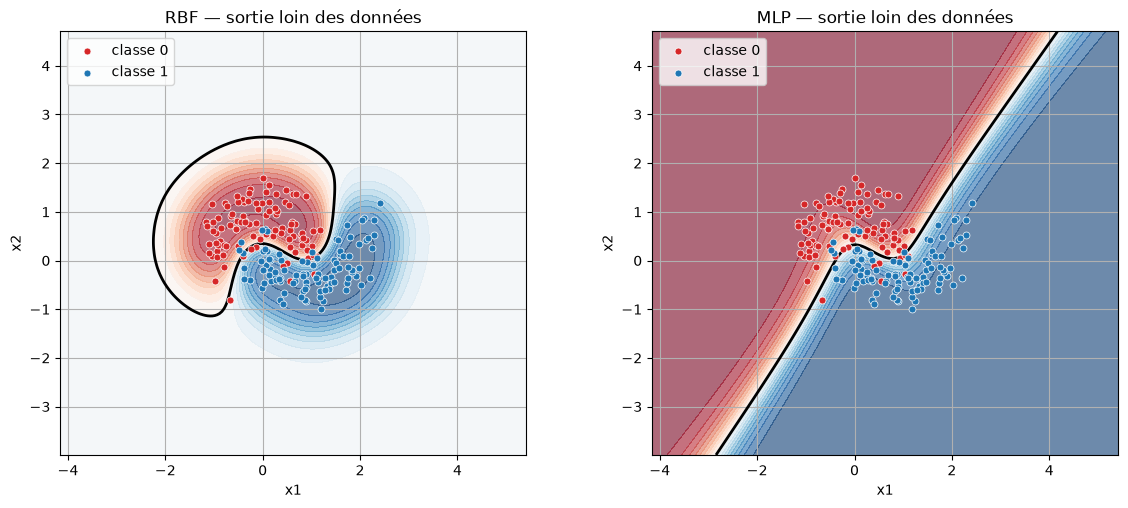

RBF: [0.53 0.53 0.53 0.53]
MLP: [0.98 0.   1.   1.  ]
sigmoid(b) du RBF : [0.53]


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, m_name in zip(axes, ("RBF", "MLP")):
    plot_decision(models["lunes"][m_name], X_mo_tr, t_mo_tr, ax=ax, margin=3.0)
    ax.set_title(f"{m_name} — sortie loin des données")
plt.show()

far = np.array([[5.0, 4.0], [-4.0, 3.0], [0.0, -5.0], [6.0, -3.0]])
for m_name in ("RBF", "MLP"):
    print(f"{m_name}: {np.round(models['lunes'][m_name].predict(far).ravel(), 2)}")
print("sigmoid(b) du RBF :", np.round(1 / (1 + np.exp(-models["lunes"]["RBF"].out.bs[0])), 2))

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 6</legend>

Que répond chaque réseau loin des données ? Expliquez la différence à partir de la forme des neurones de chaque modèle (cours, section 3).

</fieldset>

*Votre réponse :*

# TOCLEAR

Le RBF répond partout la même valeur (environ 0.53 ici) : loin des données, toutes les activations $\varphi_k(x)$ sont nulles, et la sortie vaut $\text{sigmoid}(b)$, constante. Elle ne dépend plus de la position : le réseau n'a plus aucune information sur $x$. Attention, ce n'est pas pour autant une réponse « je ne sais pas » : ici $\text{sigmoid}(b) > 0.5$, donc le RBF classe tout le plan lointain en classe 1. Cette valeur dépend du biais appris, donc de l'équilibre des classes.

Le MLP répond 0 ou 1 avec assurance selon la direction : ses neurones tanh répondent sur des demi-plans entiers, qui se prolongent à l'infini ; il extrapole sa frontière bien au-delà des données, sans aucun exemple pour la justifier. Une réponse très confiante loin des données n'est donc pas un signe de fiabilité.

## Bonus — largeur `sigma` et surapprentissage

On place maintenant **un centre sur chaque point d'entraînement** ($K = N = 200$) et on fait varier `sigma` sur les lunes. Pour choisir `sigma` sans toucher au test, on mesure l'erreur sur un jeu de **validation** séparé (1000 autres points).

Avec 200 poids de sortie, la descente de gradient est lente au pas habituel : on utilise ici un pas plus grand, `LR_BONUS = 2`.

Comme les autres réseaux du TD, chaque `RBF` est entraîné en suivant son historique ; le jeu de validation joue ici le rôle du jeu de test passé à `fit`.

In [21]:
X_bo_tr, t_bo_tr, X_bo_te, t_bo_te, X_bo_va, t_bo_va = split(*make_moons(2200, seed=1), 200, 1000)
sigmas = [0.02, 0.05, 0.15, 0.5, 1.5]
LR_BONUS = 2.0

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 7</legend>

Pour chaque valeur de `sigmas`, entraînez un `RBF` dont les centres sont **tous** les points de `X_bo_tr`, pendant `EPOCHS` époques avec le pas `LR_BONUS`, en passant le jeu de **validation** comme jeu de test à `fit` :

1. rangez l'historique renvoyé par `fit` dans `hists_sigma`, sous la clé `f"sigma = {s}"` ;
2. ajoutez à `err_train` et `err_val` le taux d'erreur final (`error_rate`) du réseau sur l'entraînement et sur la validation ;
3. rangez le réseau entraîné dans `rbfs`.

Après la vérification, la cellule suivante affiche les erreurs finales en fonction de `sigma`, puis, pour trois valeurs de `sigma`, la frontière de décision et, en dessous, les courbes d'apprentissage correspondantes.

</fieldset>

In [22]:
err_train: list[float] = []
err_val: list[float] = []
rbfs: list[RBF] = []
hists_sigma: dict[str, dict[str, list[float]]] = {}
# BEGIN
## Rappel : données X_bo_tr, t_bo_tr (entraînement), X_bo_va, t_bo_va (validation)
## for s in sigmas:
##     rbf = ...
##     hists_sigma[f"sigma = {s}"] = ...
##     ...
for s in sigmas:
    rbf = RBF(X_bo_tr, s)
    hists_sigma[f"sigma = {s}"] = rbf.fit(X_bo_tr, t_bo_tr, EPOCHS, lr=LR_BONUS, X_test=X_bo_va, t_test=t_bo_va)
    rbfs.append(rbf)
    err_train.append(error_rate(rbf, X_bo_tr, t_bo_tr))
    err_val.append(error_rate(rbf, X_bo_va, t_bo_va))
# END

In [23]:
def check_sweep():
    assert len(err_train) == len(sigmas) and len(err_val) == len(sigmas) and len(rbfs) == len(sigmas), "une valeur par sigma"
    assert all(0.0 <= e <= 1.0 for e in err_train + err_val), "les erreurs doivent être des proportions"
    assert all(len(r.centres) == len(X_bo_tr) for r in rbfs), "les centres doivent être tous les points d'entraînement"
    assert list(hists_sigma) == [f"sigma = {s}" for s in sigmas], "une clé f\"sigma = {s}\" par sigma, dans l'ordre de sigmas"
    for (key, h), r in zip(hists_sigma.items(), rbfs):
        assert len(h["train_err"]) == EPOCHS, f"{key} : entraîner pendant EPOCHS époques"
        assert len(h["test_err"]) == EPOCHS, f"{key} : passer la validation comme jeu de test à fit"
        assert h["test_err"][-1] == error_rate(r, X_bo_va, t_bo_va), f"{key} : historique de validation incorrect"
    print("balayage de sigma check — OK")

check_sweep()

balayage de sigma check — OK


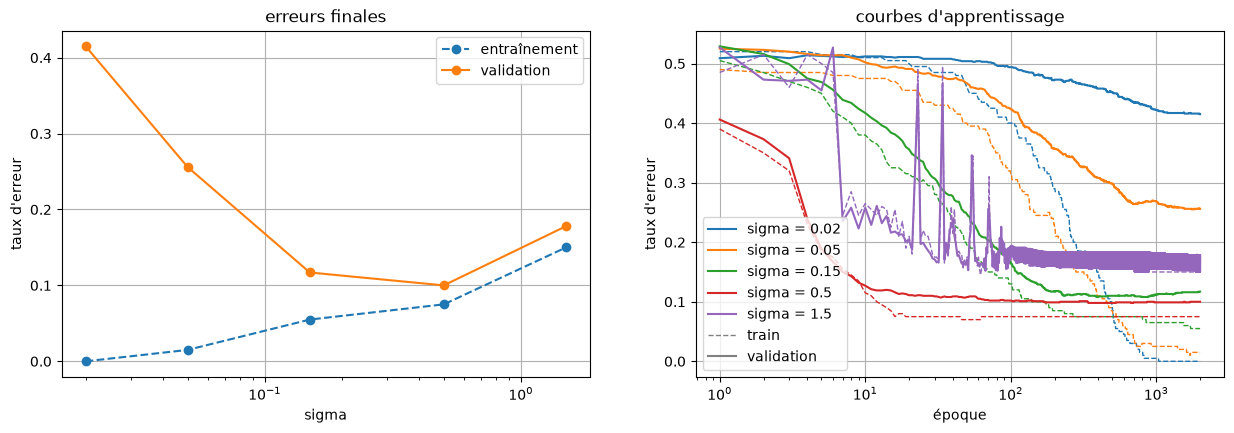

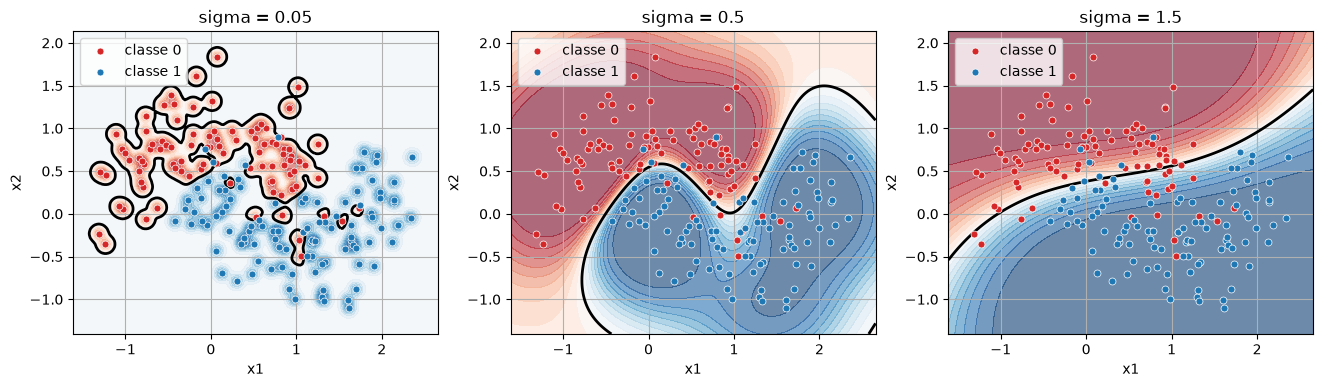

In [24]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sigmas, err_train, "o--", label="entraînement")
ax.plot(sigmas, err_val, "o-", label="validation")
ax.set_xscale("log")
ax.set_xlabel("sigma")
ax.set_ylabel("taux d'erreur")
ax.set_title("erreurs finales")
ax.legend()
ax.grid(True)
plt.show()

# frontières de décision (en haut) et courbes d'apprentissage (en dessous), pour trois valeurs de sigma
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, i in enumerate((1, 3, 4)):
    key = f"sigma = {sigmas[i]}"
    plot_decision(rbfs[i], X_bo_tr, t_bo_tr, ax=axes[0, j])
    axes[0, j].set_title(key)
    plot_curves({key: hists_sigma[key]}, metric="err", ax=axes[1, j], test_label="validation")
    axes[1, j].set_ylim(0, 0.55)
plt.tight_layout()
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 8</legend>

Pour quelles valeurs de `sigma` le réseau surapprend-il ? sous-apprend-il ? Appuyez-vous sur les erreurs finales et sur les courbes d'apprentissage (écart entre entraînement et validation au fil des époques). Quelle valeur retiendriez-vous, et sur quel jeu la mesurez-vous ?

</fieldset>

*Votre réponse :*

# TOCLEAR

Avec `sigma` petit (0.02, 0.05), chaque bosse ne couvre que son point : l'erreur d'entraînement descend jusqu'à 0 (ou presque) mais l'erreur de validation reste forte (plus de 25 %, jusqu'à 40 %). Sur les courbes, l'écart entre entraînement et validation se creuse au fil des époques : le réseau apprend les points par cœur sans progresser ailleurs. Entre les points, toutes les activations sont nulles et la sortie retombe sur $\text{sigmoid}(b)$ : c'est du **surapprentissage**. Avec `sigma` grand (1.5), toutes les bosses se ressemblent, la frontière est trop lisse et les deux erreurs restent hautes et proches : **sous-apprentissage**. (Ses courbes oscillent : les activations des 200 neurones sont presque identiques, et le pas `LR_BONUS` est trop grand pour ce problème.) On retient la valeur qui minimise l'erreur de **validation** (ici `sigma` = 0.5, où les courbes se stabilisent vite avec un faible écart), puis on mesure une seule fois l'erreur sur le test.

## Conclusion

- Le **k-NN** ne s'entraîne pas : il vote parmi les `k` plus proches voisins ; `k` règle le lissage de la frontière.
- Un **réseau RBF** est un « k-NN adouci » : chaque centre influence la sortie avec un poids qui décroît avec la distance.
- Ses neurones ont une réponse **locale** (bosse), ceux du MLP une réponse **globale** (demi-plan) : loin des données, le RBF répond une constante, le MLP extrapole avec assurance.
- L'apprentissage du RBF se fait en deux temps : les centres sont placés par k-means, sans les cibles (**non supervisé**), puis, `sigma` étant fixé, seule la couche de sortie est apprise (**supervisé**) : apprentissage rapide et simple.
- Sur des classes déséquilibrées, l'accuracy ne suffit pas à comparer des modèles : précision et rappel sont indispensables.
- `sigma` (et le nombre de centres) règle la complexité du RBF ; on le choisit sur un jeu de validation.